In [70]:
import numpy as np
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

import torch
from torch import nn

X, y = make_moons(n_samples = 500, noise = 0.2, random_state =40)

X_t = torch.tensor(X, dtype=torch.float32)
y_t = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)

X, X_test, y, y_test = train_test_split(X_t, y_t, test_size = 0.2, random_state = 30)
X.shape

torch.Size([400, 2])

In [71]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_tanh_stack = nn.Sequential(
            nn.Linear(2, 10),
            nn.Tanh(),
            nn.Linear(10, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_tanh_stack(x)
        return logits

model = NeuralNetwork()
print(model)

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_tanh_stack): Sequential(
    (0): Linear(in_features=2, out_features=10, bias=True)
    (1): Tanh()
    (2): Linear(in_features=10, out_features=1, bias=True)
    (3): Sigmoid()
  )
)


In [72]:
loss_fn = nn.BCELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.5)

In [73]:
def train(model, loss_fn, optimizer, steps=500):
    model.train()
    for step in range(steps):
        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)
    
        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

    print(f"Training\n loss: {loss.item():>7f}")

In [74]:
def test(model, loss_fn, X_test, y_test):
    model.eval()
    with torch.no_grad():
            prob = model(X_test)
            pred = (prob > 0.5).type(torch.float)
            test_loss = loss_fn(prob, y_test).item()
            correct = (pred == y_test).float().mean().item()
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

In [75]:
for step in range(10):
    train(model, loss_fn, optimizer)
    test(model, loss_fn, X_test, y_test)

Training
 loss: 0.125563
Test Error: 
 Accuracy: 96.0%, Avg loss: 0.154360 

Training
 loss: 0.087953
Test Error: 
 Accuracy: 97.0%, Avg loss: 0.140267 

Training
 loss: 0.080745
Test Error: 
 Accuracy: 97.0%, Avg loss: 0.143432 

Training
 loss: 0.078042
Test Error: 
 Accuracy: 97.0%, Avg loss: 0.145666 

Training
 loss: 0.076448
Test Error: 
 Accuracy: 97.0%, Avg loss: 0.146705 

Training
 loss: 0.075269
Test Error: 
 Accuracy: 97.0%, Avg loss: 0.147046 

Training
 loss: 0.074319
Test Error: 
 Accuracy: 97.0%, Avg loss: 0.147103 

Training
 loss: 0.073532
Test Error: 
 Accuracy: 97.0%, Avg loss: 0.147149 

Training
 loss: 0.072872
Test Error: 
 Accuracy: 97.0%, Avg loss: 0.147313 

Training
 loss: 0.072315
Test Error: 
 Accuracy: 97.0%, Avg loss: 0.147616 



In [76]:
def plot_decision_boundary(predict, X, y, title, steps = 300, pad = 0.5):
    # predict is a function that sends X to the predicted probability that y=1

    # build a grid with some padding
    x_min, x_max = X[:,0].min() - pad, X[:,0].max() + pad
    y_min, y_max = X[:,1].min() - pad, X[:,1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, steps), np.linspace(y_min, y_max, steps))

    # reshape to (N, 2) array, predict and reshape back
    grid = np.c_[xx.ravel(),yy.ravel()]
    probs = predict(grid).reshape(xx.shape)

    # draw
    plt.contourf(xx, yy, probs, levels = 50, cmap = "coolwarm", alpha = 0.6)
    plt.contour(xx, yy, probs, levels = [0.5], colors = "black", linewidths =  1.5)
    plt.scatter(X[:,0], X[:,1], c = y.ravel(), cmap = "coolwarm", edgecolors = "k", linewidths = 0.3, s = 15)
    plt.xlabel("x1")
    plt.xlabel("x2")
    plt.title(title)
    plt.show

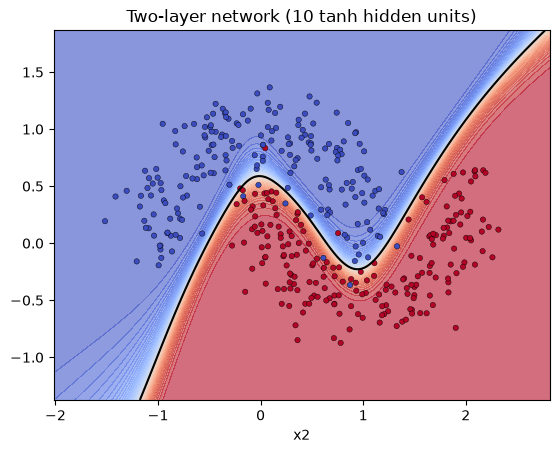

In [79]:
plot_decision_boundary(lambda P: model(torch.tensor(P, dtype=torch.float32)).detach().numpy(), X, y, title = f"Two-layer network (10 tanh hidden units)")